In [1]:
import xarray as xr
import rioxarray
import numpy as np
import matplotlib.pyplot as plt
import geopandas
from tqdm import tqdm
from shapely.geometry import box
import fiona
import rasterio
import rasterio.mask
import cartopy.crs as ccrs
import cartopy
import pandas as pd
import glob

/home/chandra/.local/lib/python3.10/site-packages/xarray/backends/cfgrib_.py:29: UserWarning: Failed to load cfgrib - most likely there is a problem accessing the ecCodes library. Try `import cfgrib` to get the full error message
  warnings.warn(


In [4]:
xr.open_dataset('/home/chandra/data/Paper4/Data_previous_literature/Cattle_density/Cattle_per_km2.tif')

<xarray.Dataset>
Dimensions:      (band: 1, x: 4320, y: 2160)
Coordinates:
  * band         (band) int64 1
  * x            (x) float64 -180.0 -179.9 -179.8 -179.7 ... 179.8 179.9 180.0
  * y            (y) float64 89.96 89.88 89.79 89.71 ... -89.79 -89.87 -89.96
    spatial_ref  int64 ...
Data variables:
    band_data    (band, y, x) float64 ...

In [2]:
Country_major_SA = geopandas.read_file('/home/chandra/data/Paper4/Data_previous_literature/SA_shape_AB2/AB0-1/SA_level0AB_Merge.shp')
Municipality_major_SA = geopandas.read_file('/home/chandra/data/Paper4/Data_previous_literature/SA_shape_AB2/AB0-1/SA_level1AB_Merge.shp')


In [3]:
Municipality = geopandas.read_file('/home/chandra/data/Paper4/Output/Base_shapefile_all_SA.shp')

In [4]:
Municipality

,Name,ID,Area (km2),geometry
0,Brazil_PR_Lupionópolis,0,120.842489,"POLYGON Z ((-51.63021 -22.66372 0.00000, -51.6..."
1,Brazil_SP_Águas de Lindóia,1,55.477991,"POLYGON Z ((-46.61019 -22.43936 0.00000, -46.6..."
2,Brazil_PA_Uruará,2,10887.473237,"POLYGON Z ((-53.85954 -2.88750 0.00000, -53.85..."
3,Brazil_RS_São Leopoldo,3,104.054283,"POLYGON Z ((-51.17861 -29.69309 0.00000, -51.1..."
4,Brazil_SP_Vargem,4,141.323371,"POLYGON Z ((-46.39678 -22.81069 0.00000, -46.3..."
...,...,...,...,...
8659,Venezuela-Zulia-San Francisco,8659,140.033844,"POLYGON Z ((-71.75827 10.53020 0.00000, -71.75..."
8660,Venezuela-Zulia-Santa Rita,8660,501.148099,"MULTIPOLYGON Z (((-71.45708 10.47912 0.00000, ..."
8661,Venezuela-Zulia-Simón Bolívar,8661,310.323544,"POLYGON Z ((-71.36958 10.24261 0.00000, -71.36..."
8662,Venezuela-Zulia-Sucre,8662,742.398931,"MULTIPOLYGON Z (((-70.99045 9.19962 0.00000, -..."


In [38]:
def Landholders(Municipality_Brazil):
    global data
    a = []
    b = []
    c = []
    Population_density_per_unit_area_croplands = Municipality_Brazil['Population_density (per km2)']*Municipality_Brazil['Area (km2)']/Municipality_Brazil['Crop area (km2)']
    Cattles_per_unit_area_pasture = Municipality_Brazil['Cattle (per km2)']/(Municipality_Brazil['Pasture area (km2)']/Municipality_Brazil['Area (km2)'])
    for i in tqdm(range(Municipality_Brazil.shape[0])):
        a.append('Blank')
        b.append('Blank')
        c.append('Blank')
        
    ##### Crop analysis            
    for i in tqdm(range(Municipality_Brazil.shape[0])):
        data = Municipality_Brazil.iloc[i]
        if data['Crop area (km2)'] == 0:
            a[i] = np.nan
            continue
        if data['Crop area (km2)'] <= 1:
            a[i] = 'Crop-Small'
            continue
        if (data['Crop area (km2)']  > 1) & (data['Crop area (km2)'] <=25):
            a[i] = 'Crop-Medium'
            continue
        if (data['Crop area (km2)']  > 25):
            a[i] = 'Crop-Large'
            continue
        else:
            a[i] = 'Crop (Check)'  

    for i in tqdm(range(Municipality_Brazil.shape[0])):
        data = Municipality_Brazil.iloc[i]
        if (Population_density_per_unit_area_croplands[i] > 50) & (a[i] == 'Crop-Large'):
            a[i] = 'Crop-Small'
            continue
    
    for i in tqdm(range(Municipality_Brazil.shape[0])):
        data = Municipality_Brazil.iloc[i]
        if (data['Forest area (km2)']/ data['Area (km2)'] > 0.90):
            a[i] = 'Remote'
    
    
    ##### Pasture analysis            
    for i in tqdm(range(Municipality_Brazil.shape[0])):
        data = Municipality_Brazil.iloc[i]
        if data['Pasture area (km2)'] == 0:
            b[i] = np.nan
            continue
        if (Cattles_per_unit_area_pasture[i] == np.nan) | (Cattles_per_unit_area_pasture[i] == np.inf):
            b[i] = np.nan
            continue
        if (Cattles_per_unit_area_pasture[i] > 30) | (data['Cattle (per km2)']  > 15):
            b[i] = 'Pasture-Large'
            continue
        if Cattles_per_unit_area_pasture[i] <= 10:
            b[i] = 'Pasture-Small'
            continue
        if (Cattles_per_unit_area_pasture[i] > 10) & (Cattles_per_unit_area_pasture[i] <=30):
            b[i] = 'Pasture-Medium'
            continue
        else:
            b[i] = 'Pasture (Check)'
            
    for i in tqdm(range(Municipality_Brazil.shape[0])):
        data = Municipality_Brazil.iloc[i]
        if (data['Forest area (km2)']/ data['Area (km2)'] > 0.90):
            b[i] = 'Remote'
            continue
        if (data['Other area (km2)']/ data['Area (km2)'] > 0.70):
            b[i] = 'Remote (Other)'
    
    
    for i in tqdm(range(Municipality_Brazil.shape[0])):
        """
        if b[i] == 'Remote (Other)':
            c[i] = 'Remote (Other)'
            continue
        """
        if (a[i] == 'Remote (Other)') & (b[i] == 'Crop-Small'):
            c[i] = ' Small'
            continue
        if (a[i] == 'Crop-Small') & (b[i] == 'Remote (Other)'):
            c[i] = ' Small'
            continue
        if (a[i] == 'Remote (Other)') & (b[i] == 'Crop-Medium'):
            c[i] = ' Medium'
            continue
        if (a[i] == 'Crop-Medium') & (b[i] == 'Remote (Other)'):
            c[i] = ' Medium'
            continue
        if (a[i] == 'Remote (Other)') & (b[i] == 'Crop-Large'):
            c[i] = ' Large'
            continue
        if (a[i] == 'Crop-Large') & (b[i] == 'Remote (Other)'):
            c[i] = ' Large'
            continue
        if (a[i] == 'Remote') & (b[i] == 'Remote'):
            c[i] = 'Remote (Forest)'
            continue
        if (a[i] == 'Crop-Small') & (b[i] == 'Pasture-Small'):
            c[i] = ' Small'
            continue
        if ((a[i] == 'Remote') & (b[i] == 'Pasture-Small') | (a[i] == 'Crop-Small') & (b[i] == 'Remote')):
            c[i] = ' Small'
            continue
        if ((a[i] == 'Crop-Small') & pd.isna(b[i])) | (pd.isna(a[i]) & (b[i] == 'Pasture-Small')):
            c[i] = ' Small'
            continue
        if (a[i] == 'Crop-Medium') & (b[i] == 'Pasture-Medium'):
            c[i] = ' Medium'
            continue
        if ((a[i] == 'Remote') & (b[i] == 'Pasture-Medium') | (a[i] == 'Crop-Medium') & (b[i] == 'Remote')):
            c[i] = ' Medium'
            continue
        if ((a[i] == 'Crop-Medium') & pd.isna(b[i])) | (pd.isna(a[i]) & (b[i] == 'Pasture-Medium')):
            c[i] = ' Medium'
            continue
        if (a[i] == 'Crop-Large') & (b[i] == 'Pasture-Large'):
            c[i] = ' Large'
            continue
        if ((a[i] == 'Remote') & (b[i] == 'Pasture-Large') | (a[i] == 'Crop-Large') & (b[i] == 'Remote')):
            c[i] = ' Large'
            continue
        if ((a[i] == 'Crop-Large') & pd.isna(b[i])) | (pd.isna(a[i]) & (b[i] == 'Pasture-Large')):
            c[i] = ' Large'
            continue
        if (pd.isna(b[i]) & pd.isna(a[i])):
            c[i] = 'Remote (Other)'
            continue
        if (pd.isna(a[i])) & (b[i] == 'Remote (Other)'):
            c[i] = 'Remote (Other)'
        else:
            c[i] = 'Check'
        
    for i in tqdm(range(Municipality_Brazil.shape[0])):
        data = Municipality_Brazil.iloc[i]
        if c[i] == 'Check':
            for Class_crop in ['Crop-Small', 'Crop-Medium', 'Crop-Large']:
                for Class_pasture in ['Pasture-Small', 'Pasture-Medium', 'Pasture-Large']:
                    if Class_crop == Class_pasture:
                        continue
                    else:
                        if (data['Crop area (km2)']/data['Area (km2)'] >= data['Pasture area (km2)']/data['Area (km2)']):
                            #c[i] = ' '+Class_crop.split('-', 1)[1]
                            c[i] = ' '+data['Dominance-crop'].split('-', 1)[1]
                            continue
                        if (data['Crop area (km2)']/data['Area (km2)'] < data['Pasture area (km2)']/data['Area (km2)']):
                            #c[i] = ' '+Class_pasture.split('-', 1)[1]
                            c[i] = ' '+data['Dominance-pasture'].split('-', 1)[1]
                            continue
                        else:
                            c[i] = 'Check-2'
    return a,b,c

In [7]:
with fiona.open('/home/chandra/data/Paper4/Output/Base_shapefile_all_SA.shp', "r") as shapefile:
    shapes = [feature["geometry"] for feature in shapefile]

In [8]:
Area_crop = []
Area_pasture = []
Area_forest = []
Area_water = []
Area_other = []
cattle_per_km2 = []

for i in tqdm(range(Municipality.shape[0])):
    with rasterio.open("/home/chandra/data/Paper4/Data_previous_literature/hildap_vGLOB-1.0_geotiff_wgs84/hildap_GLOB-v1.0_lulc-states/hilda_plus_2016_states_GLOB-v1-0_wgs84-nn.tif") as src:
        out_image, out_transform = rasterio.mask.mask(src, [shapes[i]], crop=True)
        out_meta = src.meta
    urban = 0
    urban = np.where(out_image[0] == 11, 1, np.nan)
    crop = 0
    crop = np.where(out_image[0] == 22, 1, np.nan)
    pasture = 0
    pasture = np.where(out_image[0] == 33, 1, np.nan)
    forest = 0
    forest = np.where(out_image[0] == 44, 1, np.nan)
    water = 0
    water = np.where(out_image[0] == 77, 1, np.nan)
    other_1 = 0
    other_1 = np.where(out_image[0] == 55, 1, np.nan)
    other_2 = 0
    other_2 = np.where(out_image[0] == 66, 1, np.nan)
    
    with rasterio.open('/home/chandra/data/Paper4/gridarea_180.tif') as src:
        out_image, out_transform = rasterio.mask.mask(src, [shapes[i]], crop=True)
        out_meta = src.meta

    Area_crop.append(np.nansum(crop*out_image[0]/1000000)) # Converting m2 to km2
    Area_pasture.append(np.nansum(pasture*out_image[0]/1000000)) # Converting m2 to km2
    Area_forest.append(np.nansum(forest*out_image[0]/1000000)) # Converting m2 to km2
    Area_water.append(np.nansum(water*out_image[0]/1000000)) # Converting m2 to km2
    Area_other.append(np.nansum(other_1*out_image[0]/1000000)+np.nansum(other_2*out_image[0]/1000000)+np.nansum(urban*out_image[0]/1000000))
    
    with rasterio.open('/home/chandra/data/Paper4/Data_previous_literature/Cattle_density/Cattle_per_km2.tif') as src:
        out_image, out_transform = rasterio.mask.mask(src, [shapes[i]], crop=True)
        out_meta = src.meta
    #cattle_per_km2.append(np.nansum(out_image[0]))
    cattle_per_km2.append(np.nanmean(out_image[0]))

Municipality['Crop area (km2)'] = Area_crop
Municipality['Pasture area (km2)'] = Area_pasture
Municipality['Forest area (km2)'] = Area_forest
Municipality['Water area (km2)'] = Area_water
Municipality['Other area (km2)'] = Area_other
Municipality['Cattle (per km2)'] = cattle_per_km2

100%|██████████| 8664/8664 [09:40<00:00, 14.92it/s]  


In [9]:
# Population density
Population_density = []
for i in tqdm(range(Municipality.shape[0])):
    with rasterio.open("/home/chandra/data/Paper4/Data_previous_literature/Population_desnity/Population-density_2020.tif") as src:
        out_image, out_transform = rasterio.mask.mask(src, [shapes[i]], crop=True)
        out_meta = src.meta
    out_image = np.where(out_image[0] < 0, np.nan, out_image[0])
    if np.nanmean(out_image) >= 0:
        Population_density.append(np.nanmean(out_image))
    else:
        Population_density.append(0)
Municipality['Population_density (per km2)'] = Population_density

  6%|▋         | 544/8664 [00:08<02:03, 65.74it/s] /tmp/ipykernel_3563163/489401313.py:8: RuntimeWarning: Mean of empty slice
  if np.nanmean(out_image) >= 0:
 96%|█████████▌| 8306/8664 [01:27<00:02, 152.55it/s]/tmp/ipykernel_3563163/489401313.py:8: RuntimeWarning: Mean of empty slice
  if np.nanmean(out_image) >= 0:
100%|██████████| 8664/8664 [01:30<00:00, 96.04it/s] 


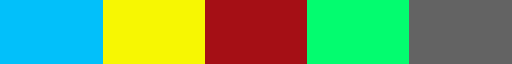

In [10]:
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
cmap = ListedColormap(["#a50f15",'#f7f702','#02c0fa','#03fc6f'])
cmap

cmap2 = ListedColormap(["#a50f15",'#f7f702','#02c0fa','#03fc6f', '#636363'])
cmap2

cmap3 = ListedColormap(['#02c0fa','#f7f702',"#a50f15",'#03fc6f', '#636363'])
cmap3

In [39]:
Municipality['Dominance-crop'], Municipality['Dominance-pasture'], Municipality['Dominance'] = Landholders(Municipality)


Municipality['Dominance'] = Municipality['Dominance'].replace(to_replace=' Small', value = 1)
Municipality['Dominance'] = Municipality['Dominance'].replace(to_replace=' Medium', value = 2)
Municipality['Dominance'] = Municipality['Dominance'].replace(to_replace=' Large', value = 3)
Municipality['Dominance'] = Municipality['Dominance'].replace(to_replace='Remote (Forest)', value = 4)
Municipality['Dominance'] = Municipality['Dominance'].replace(to_replace='Remote (Other)', value = 5)

100%|██████████| 8664/8664 [00:04<00:00, 1889.46it/s]


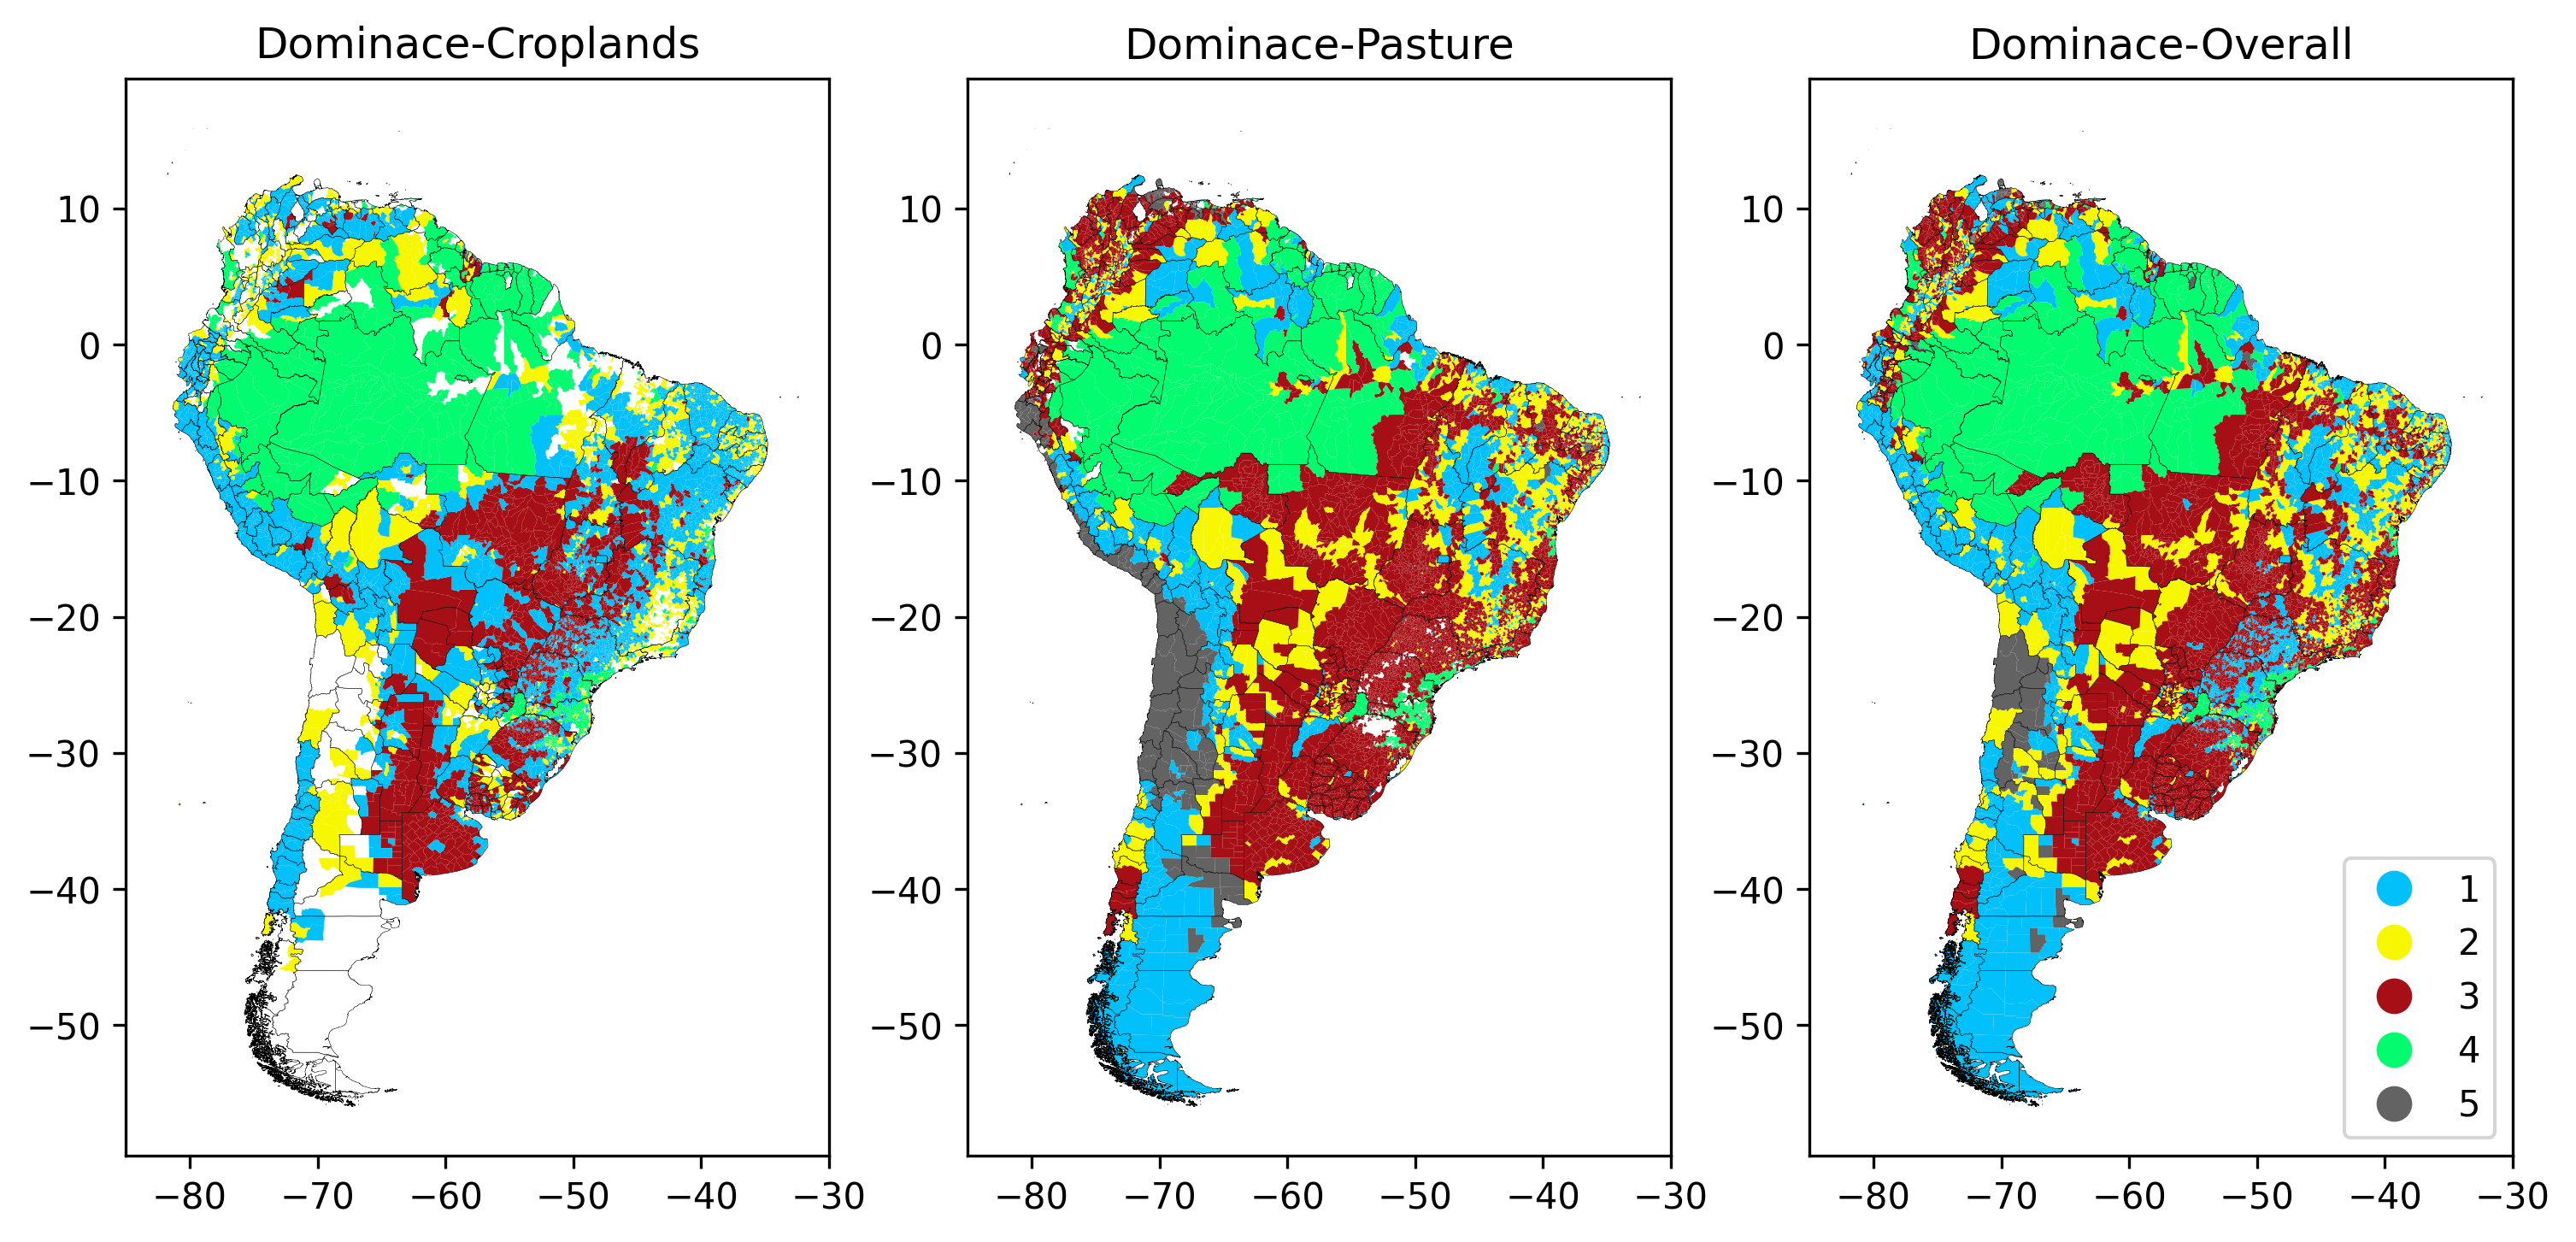

In [40]:
fig, ax = plt.subplots(1,3, figsize=(10,18), dpi = 300)

Municipality.plot(column = 'Dominance-crop', legend = False, cmap = cmap, ax = ax[0])
Municipality.plot(column = 'Dominance-pasture', legend = False, cmap = cmap2, ax = ax[1])
Municipality.plot(column = 'Dominance', legend = True, cmap = cmap3, ax = ax[2], categorical=True, legend_kwds={'loc': 'lower right'})
#ax[2].legend(['Smallholders', 'Medium landholders', 'Large landholders', 'Remote (Forest)', 'Remote (Others)'])

ax[0].set_title('Dominace-Croplands')
ax[1].set_title('Dominace-Pasture')
ax[2].set_title('Dominace-Overall')

Municipality_major_SA.plot(column = 'NAME_1', edgecolor = 'k', facecolor = 'None', ax = ax[0], lw = 0.1)
Municipality_major_SA.plot(column = 'NAME_1', edgecolor = 'k', facecolor = 'None', ax = ax[1], lw = 0.1)
Municipality_major_SA.plot(column = 'NAME_1', edgecolor = 'k', facecolor = 'None', ax = ax[2], lw = 0.1)

for i in range(3):
    ax[i].set_xlim(-85, -30)
plt.tight_layout()

In [13]:
# Get CSV files list from a folder
path = '/home/chandra/data/Paper4/Data_previous_literature/Deforestation_data_gee'
csv_files = glob.glob(path + "/*.csv")

# Read each CSV file into DataFrame
# This creates a list of dataframes
df_list = (pd.read_csv(file) for file in csv_files)

# Concatenate all DataFrames
big_df   = pd.concat(df_list, ignore_index=True)
big_df = big_df.sort_values(by = 'ID')

In [14]:
big_df = big_df.reset_index()

In [15]:
big_df.rename(columns = {'ID': 'ID1'}, inplace = True)

In [16]:
Municipality = pd.concat([Municipality, big_df], axis=1)

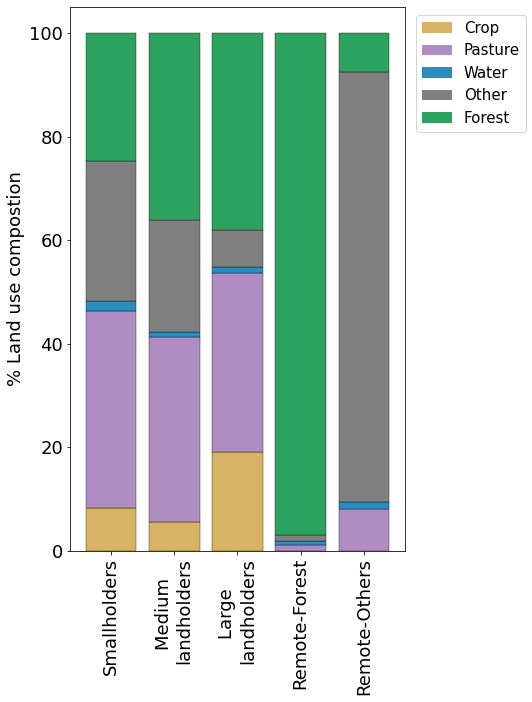

In [41]:
fig = plt.figure(figsize=(6, 10))
ax = fig.add_subplot(111)
# create data
x = [1,2,3,4,5]
array = {}
color = ['#d8b365','#af8dc3','#2b8cbe', 'grey', '#2ca25f']
landuse = [ "Crop", "Pasture", "Water", "Other", "Forest"]
for dominance in x:
    a = []
    for j in landuse:
        a.append(Municipality[j+' area (km2)'].where(Municipality['Dominance'] == dominance).sum())
    array[dominance] = np.array(a)
    array[dominance] = array[dominance]/(array[dominance].sum())*100 #remove this line for aboslute values
array = pd.DataFrame([array[x[0]], array[x[1]], array[x[2]], array[x[3]], array[x[4]]], columns=[landuse])
  
# plot bars in stack manner
array.plot(y = landuse, kind='bar', stacked=True, ax = ax, 
           legend = False, color = color, width = 0.8, edgecolor = 'black', lw = 0.35)
ax.set_ylabel('% Land use compostion', fontsize = 18)
ax.set_xticklabels(['Smallholders','Medium \nlandholders','Large \nlandholders','Remote-Forest', 'Remote-Others'])
ax.tick_params(axis='both', which='major', labelsize=18)
ax.tick_params(axis='x', labelrotation=90)
#ax.set_ylim(0,100)
## Plotting ecoregion legend
#Ecozone_unique_name = [ "Crop", "Pasture", "Water", "Other", "Forest"]

import matplotlib.patches as mpatches
from matplotlib.font_manager import FontProperties

recs = []
for i in range(0,len(color)):
    recs.append(mpatches.Rectangle((0,0),1,1,fc=(color)[i]))
fontP = FontProperties()
fontP.set_size('15')
plt.legend(recs,landuse, ncol = 1,prop=fontP, bbox_to_anchor=(1.01, 1))

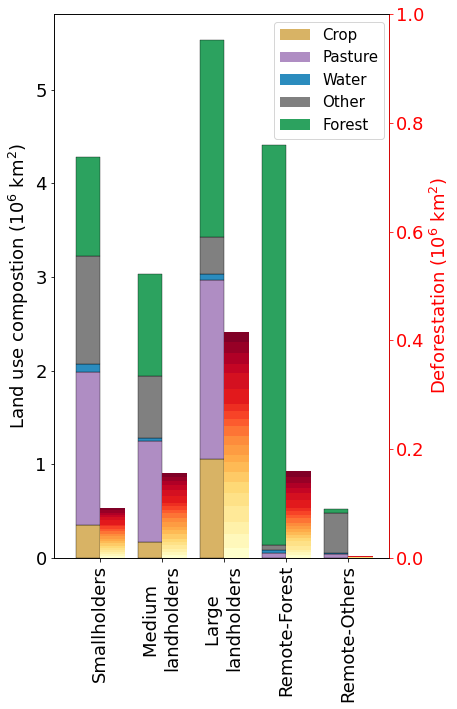

In [42]:
fig = plt.figure(figsize=(6, 10))
ax = fig.add_subplot(111)
ax2 = ax.twinx()
# create data
x = [1,2,3,4,5]
array = {}
color = ['#d8b365','#af8dc3', '#2b8cbe', 'grey', '#2ca25f']
landuse = [ "Crop", "Pasture", "Water", "Other", "Forest"]
for dominance in x:
    a = []
    for j in landuse:
        a.append(Municipality[j+' area (km2)'].where(Municipality['Dominance'] == dominance).sum())
    array[dominance] = np.array(a)
    #array[dominance] = array[dominance]/(array[dominance].sum())*100 #remove this line for aboslute values
array = pd.DataFrame([array[x[0]], array[x[1]], array[x[2]], array[x[3]], array[x[4]]], columns=[landuse])
array = array/1000000
# plot bars in stack manner
array.plot(y = landuse, kind='bar', stacked=True, ax = ax, 
           legend = False, color = color, align='edge',width = -0.4, edgecolor = 'black', lw = 0.35)
ax.set_ylabel(r'Land use compostion (10$^{6}$ km${^2}$)', fontsize = 18)
ax.set_xticklabels(['Smallholders','Medium \nlandholders','Large \nlandholders','Remote-Forest', 'Remote-Others'])
ax.tick_params(axis='both', which='major', labelsize=18)
ax.tick_params(axis='x', labelrotation=90)


import matplotlib.patches as mpatches
from matplotlib.font_manager import FontProperties
recs = []
for i in range(0,len(color)):
    recs.append(mpatches.Rectangle((0,0),2,2,fc=(color)[i]))
fontP = FontProperties()
fontP.set_size('15')
ax.legend(recs,landuse, ncol = 1,prop=fontP, bbox_to_anchor=(1.01, 1))

# create data
array_1 = {}
landuse = np.arange(2001,2022,1)
landuse = list(map(str, landuse))
k = 0 ## connects to total sum array
for dominance in x:
    a = []
    for j in landuse:
        a.append(Municipality['loss_'+str(j)].where(Municipality['Dominance'] == dominance).sum())
    array_1[dominance] = np.array(a)
    #array_1[dominance] = array_1[dominance]/array.iloc[k].sum()*100 #remove this line for aboslute values
    k = k+1
array_1 = pd.DataFrame([array_1[x[0]], array_1[x[1]], array_1[x[2]], array_1[x[3]], array_1[x[4]]], columns=[landuse])
array_1 = array_1/1000000
# plot bars in stack manner
array_1.plot(y = landuse, kind='bar', stacked=True, ax = ax2, 
           legend = False, cmap = 'YlOrRd', align='edge',width = 0.4)
ax2.set_ylabel('Deforestation (10$^{6}$ km${^2}$)', fontsize = 18)
ax2.set_xticklabels(['Smallholders','Medium \nlandholders','Large \nlandholders','Remote-Forest', 'Remote-Others'])
ax2.tick_params(axis='both', which='major', labelsize=18)
ax2.tick_params(axis='x', labelrotation=90)
ax2.set_xlim(-0.75,)
ax2.set_ylim(0,1)
ax2.yaxis.label.set_color('red')
ax2.spines["right"].set_edgecolor('red')
ax2.tick_params(axis='y', colors='red')

In [43]:
Municipality.to_file('/home/chandra/data/Paper4/Output/Actor_dominance_HILDA+.shp', mode="w")

/tmp/ipykernel_3563163/1544705752.py:1: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  Municipality.to_file('/home/chandra/data/Paper4/Output/Actor_dominance_HILDA+.shp', mode="w")


In [44]:
from geocube.api.core import make_geocube
out_grid = make_geocube(
    vector_data=Municipality[['Dominance', 'geometry']],
    measurements=['Dominance'],
    resolution=(-0.50, 0.50)
)
out_grid

<xarray.Dataset>
Dimensions:      (y: 144, x: 162)
Coordinates:
  * y            (y) float64 15.75 15.25 14.75 14.25 ... -54.75 -55.25 -55.75
  * x            (x) float64 -109.2 -108.8 -108.2 ... -29.75 -29.25 -28.75
    spatial_ref  int64 0
Data variables:
    Dominance    (y, x) float64 nan nan nan nan nan nan ... nan nan nan nan nan

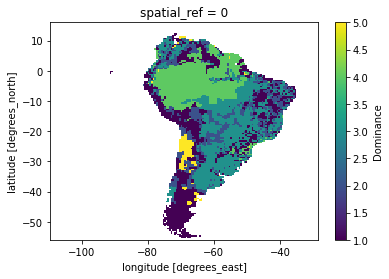

In [45]:
out_grid['Dominance'].plot()

In [47]:
out_grid.to_netcdf('/home/chandra/data/Paper4/Output/Actor_dominance_HILDA+.nc')

In [58]:

# This creates a list of dataframes
df_list = geopandas.read_file('/home/chandra/data/Paper4/Output/Actor_dominance_Mapbiomas.shp')
# Concatenate all DataFrames
df_list = df_list[['ID']]

In [66]:
Municipality_trimmed = pd.merge(Municipality, df_list, on="ID", how="inner")
Municipality_trimmed.to_file('/home/chandra/data/Paper4/Output/Actor_dominance_HILDA+_trimmed.shp', mode="w")

/tmp/ipykernel_3563163/155293654.py:2: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  Municipality_trimmed.to_file('/home/chandra/data/Paper4/Output/Actor_dominance_HILDA+_trimmed.shp', mode="w")


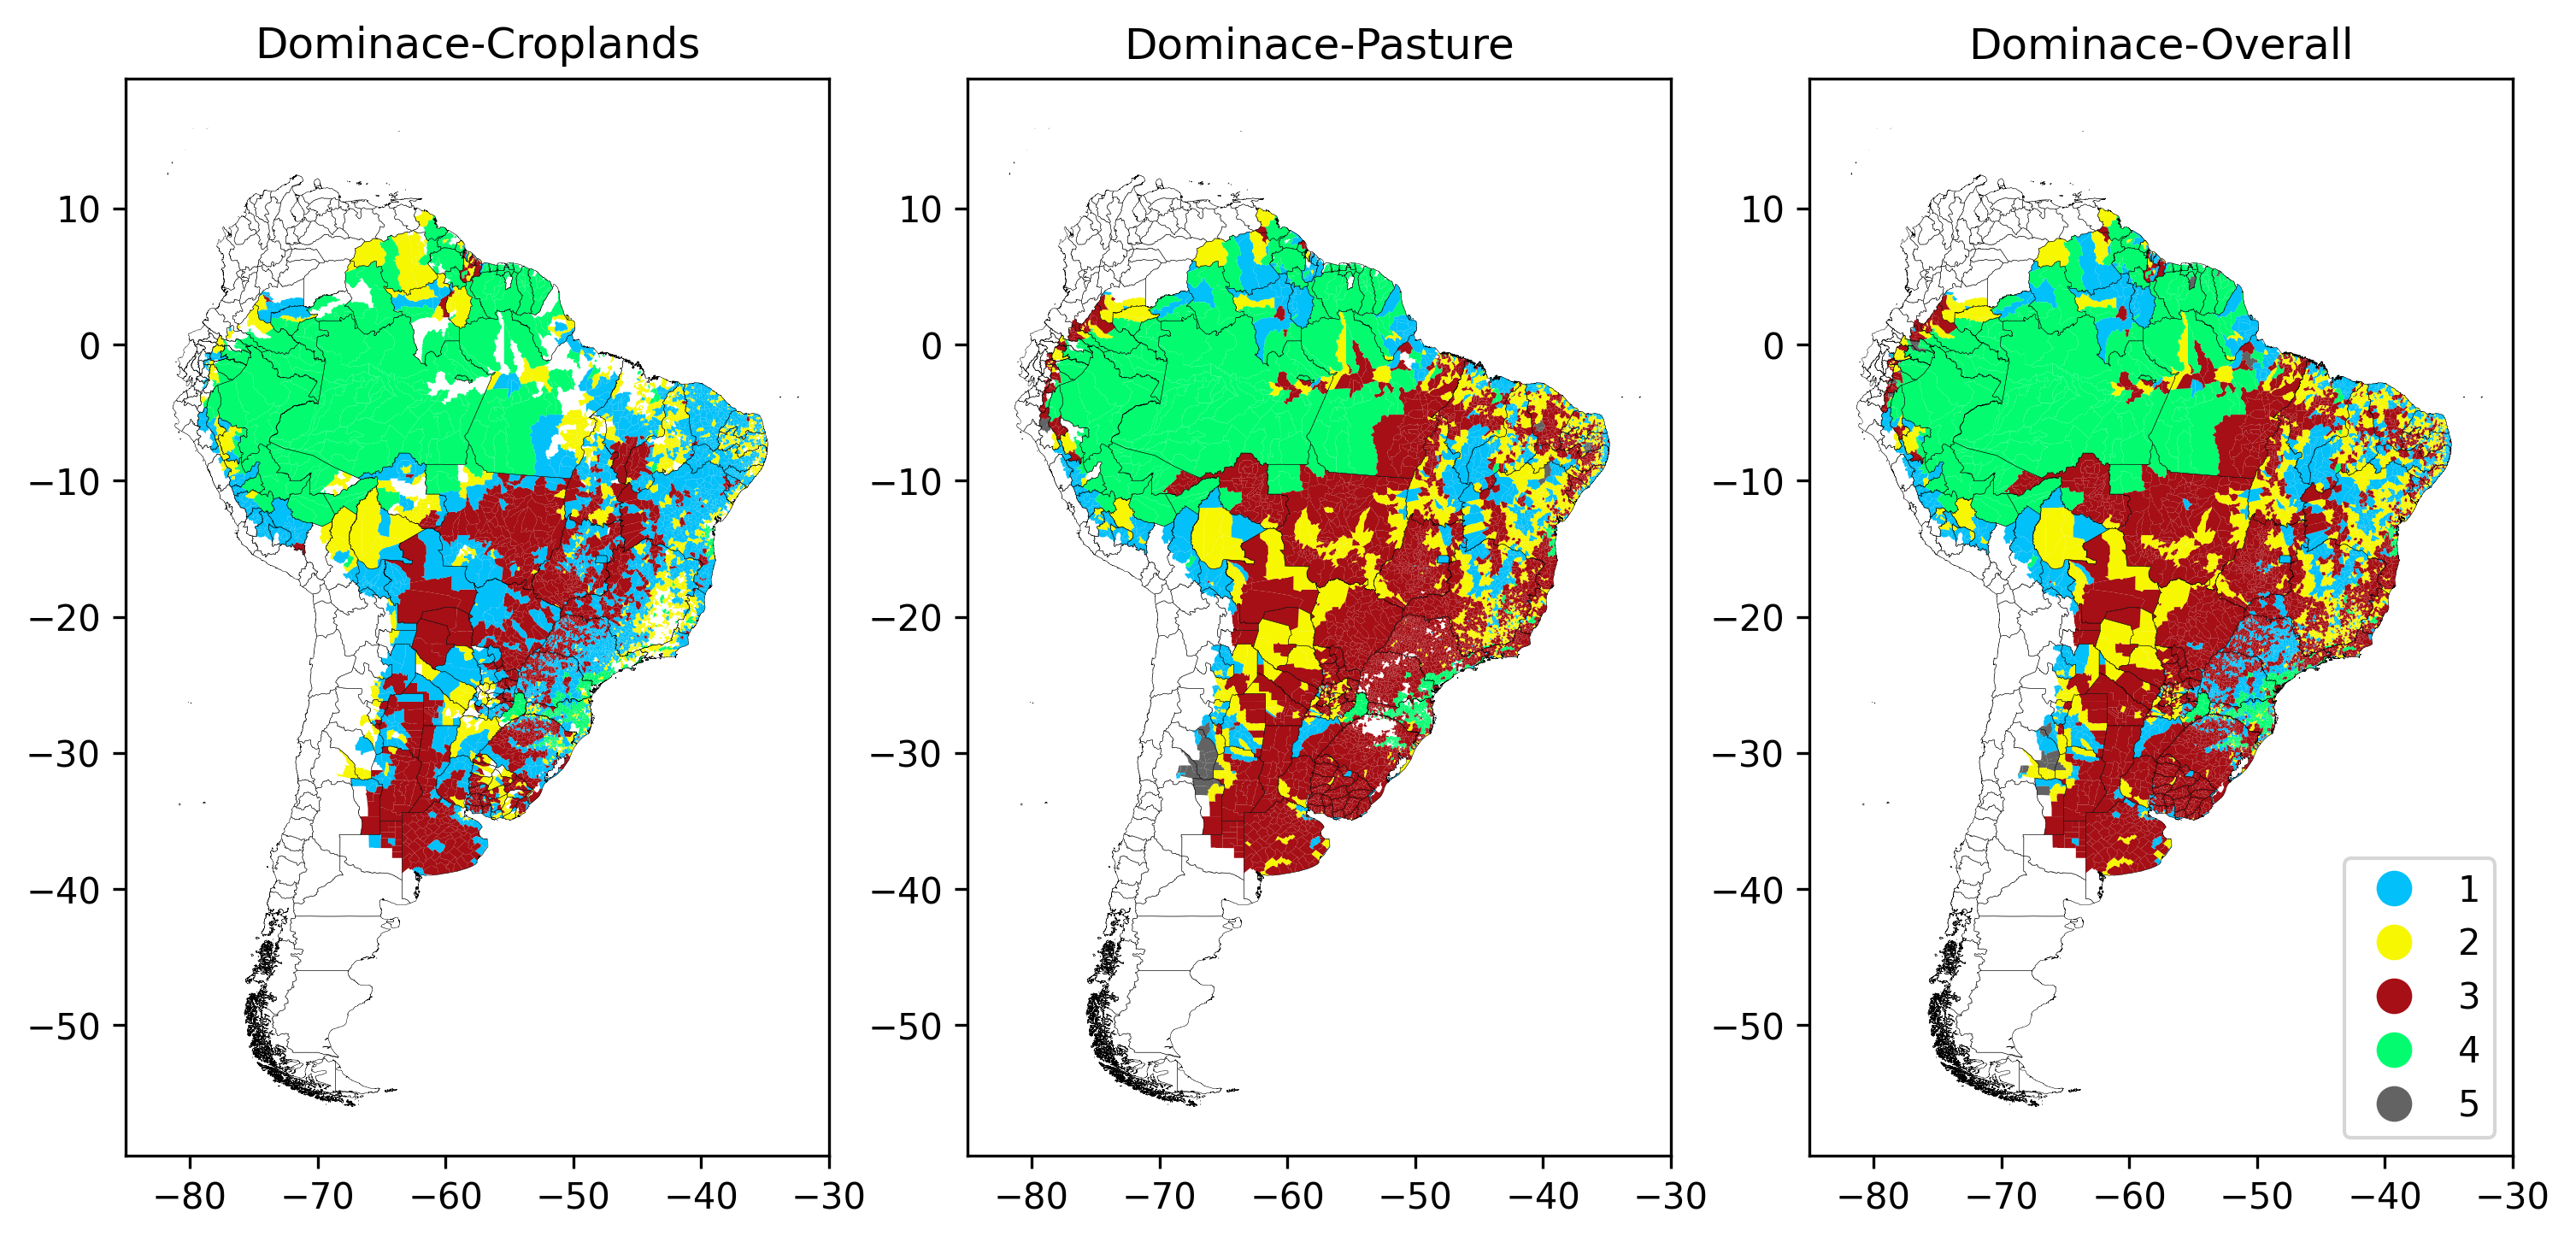

In [72]:
fig, ax = plt.subplots(1,3, figsize=(10,18), dpi = 300)

Municipality_trimmed.plot(column = 'Dominance-crop', legend = False, cmap = cmap, ax = ax[0])
Municipality_trimmed.plot(column = 'Dominance-pasture', legend = False, cmap = cmap2, ax = ax[1])
Municipality_trimmed.plot(column = 'Dominance', legend = True, cmap = cmap3, ax = ax[2], categorical=True, legend_kwds={'loc': 'lower right'})
#ax[2].legend(['Smallholders', 'Medium landholders', 'Large landholders', 'Remote (Forest)', 'Remote (Others)'])

ax[0].set_title('Dominace-Croplands')
ax[1].set_title('Dominace-Pasture')
ax[2].set_title('Dominace-Overall')

Municipality_major_SA.plot(column = 'NAME_1', edgecolor = 'k', facecolor = 'None', ax = ax[0], lw = 0.1)
Municipality_major_SA.plot(column = 'NAME_1', edgecolor = 'k', facecolor = 'None', ax = ax[1], lw = 0.1)
Municipality_major_SA.plot(column = 'NAME_1', edgecolor = 'k', facecolor = 'None', ax = ax[2], lw = 0.1)

for i in range(3):
    ax[i].set_xlim(-85, -30)
plt.tight_layout()

In [67]:
from geocube.api.core import make_geocube
out_grid = make_geocube(
    vector_data=Municipality_trimmed[['Dominance', 'geometry']],
    measurements=['Dominance'],
    resolution=(-0.50, 0.50)
)
out_grid

<xarray.Dataset>
Dimensions:      (y: 100, x: 101)
Coordinates:
  * y            (y) float64 10.25 9.75 9.25 8.75 ... -38.25 -38.75 -39.25
  * x            (x) float64 -79.25 -78.75 -78.25 ... -30.25 -29.75 -29.25
    spatial_ref  int64 0
Data variables:
    Dominance    (y, x) float64 nan nan nan nan nan nan ... nan nan nan nan nan

In [71]:
out_grid.to_netcdf('/home/chandra/data/Paper4/Output/Actor_dominance_HILDA+_trimmed.nc')

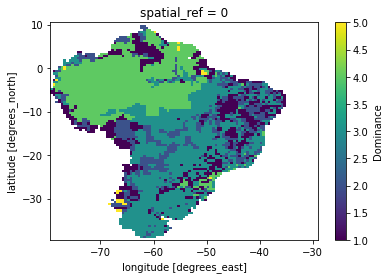

In [70]:
out_grid['Dominance'].plot()